#PRE_ENTREGA - Número 3- Grupo 11
Integrantes: Biaiñ Joaquin, Facenda Selena y Ferreyra Iara


## 1. Preparación de los Datos y Preprocesamiento (ColumnTransformer y Pipeline)

En esta sección vamos a definir nuestra variable objetivo (`Y`) y nuestras variables predictoras (`X`).
Luego, construimos un pipeline de preprocesamiento que se encargará de escalar las variables numéricas y procesar las categórias de forma limpia y automatizada.

In [1]:
import pandas as pd

# Cargar el dataset para asegurar la disponibilidad de la variable df
df = pd.read_csv("facies_data.csv")

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Definir Features (X) y Target (y)
# Excluimos 'Facies' (nuestro target), y columnas de identificación que no aportan al patrón físico como 'Well Name' o 'Depth' según corresponda.
# Mantendremos las principales variables petrofísicas y geológicas:
features = ['GR', 'ILD_log10', 'DeltaPHI', 'PHIND', 'PE', 'NM_M', 'RELPOS']
target = 'Facies'

X = df[features]
y = df[target]

# 2. Separar variables numéricas y categóricas/binarias
numeric_features = ['GR', 'ILD_log10', 'DeltaPHI', 'PHIND', 'PE', 'RELPOS']
categorical_features = ['NM_M'] # NM_M actúa como indicador de ambiente (1 o 2)

# 3. Construir el Preprocesador con ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# 4. División inicial de los datos en Train y Test (reservando un 20% para la evaluación final)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (2585, 7)
Dimensiones de X_test: (647, 7)


# 2. Entrenar un Modelo Baseline (Línea de Base)
Ahora que ya tenemos el preprocesado listo, el siguiente paso es entrenar un modelo sencillo pero robusto para que nos sirva de punto de comparación es decir realizar un **baseline**.

 Para la clasificación de las facies litologicas, un Random Forest o un Árbol de decisión funcionarán bien de entrada.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Crear el Pipeline completo uniendo el preprocesador y el modelo de Machine Learning
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# 2. Entrenar el modelo con los datos de entrenamiento
model_pipeline.fit(X_train, y_train)

# 3. Realizar predicciones sobre el conjunto de test
y_pred = model_pipeline.predict(X_test)

# 4. Evaluar el rendimiento
print("Accuracy (Exactitud) del Baseline:", accuracy_score(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

Accuracy (Exactitud) del Baseline: 0.7372488408037094

Reporte de Clasificación:
              precision    recall  f1-score   support

           1       0.82      0.71      0.76        52
           2       0.75      0.80      0.77       148
           3       0.76      0.77      0.77       123
           4       0.77      0.73      0.75        37
           5       0.65      0.56      0.60        43
           6       0.64      0.68      0.66        92
           7       0.88      0.75      0.81        20
           8       0.70      0.71      0.70       100
           9       0.90      0.84      0.87        32

    accuracy                           0.74       647
   macro avg       0.76      0.73      0.74       647
weighted avg       0.74      0.74      0.74       647



Viendo el Reporte de Clasificación, se puede ver que **facies como la 9 y la 7** tienen un F1-score muy alto (0.87 y 0.81), lo que significa que el modelo las distingue con bastante facilidad.


Las **facies 5 y 6** son las que más le cuestan al modelo (con F1-scores de 0.60 y 0.66), algo súper común en este dataset debido a la similitud en las respuestas de los registros eléctricos para esas litofacies específicas.


## 3. Optimización del Modelo mediante GridSearchCV

Con el fin de mejorar el rendimiento del baseline y evitar el sobreajuste (overfitting), el cual ocurre cuando un modelo de aprendizaje automático se ajusta demasiado bien a los datos de entrenamiento y no generaliza bien a datos nuevos,implementaremos una búsqueda de hiperparámetros combinada con validación cruzada (Cross-Validation).

In [ ]:
from sklearn.model_selection import GridSearchCV

# 1. Definir la grilla de hiperparámetros a explorar
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5]
}

# 2. Configurar GridSearchCV con validación cruzada de 5 particiones (folds)
grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# 3. Ejecutar la búsqueda con los datos de entrenamiento
grid_search.fit(X_train, y_train)

# 4. Mostrar los mejores parámetros encontrados y el score obtenido
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)
print(f"\nAccuracy promedio en validación cruzada: {grid_search.best_score_:.4f}")

# 5. Evaluar el mejor modelo en el conjunto de testeo
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

print("\nReporte de Clasificación del Modelo Optimizado:")
print(classification_report(y_test, y_pred_tuned))

Mejores hiperparámetros encontrados:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Accuracy promedio en validación cruzada: 0.7157

Reporte de Clasificación del Modelo Optimizado:
              precision    recall  f1-score   support

           1       0.84      0.69      0.76        52
           2       0.75      0.81      0.78       148
           3       0.77      0.78      0.78       123
           4       0.72      0.70      0.71        37
           5       0.65      0.51      0.57        43
           6       0.62      0.68      0.65        92
           7       0.88      0.75      0.81        20
           8       0.69      0.71      0.70       100
           9       1.00      0.88      0.93        32

    accuracy                           0.74       647
   macro avg       0.77      0.72      0.74       647
weighted avg       0.74      0.74      0.74       647



**classifier__n_estimators**: Indica cuántos árboles de decisión individuales va a construir el Random Forest. Probamos con 50, 100 y 200 árboles.

**classifier__max_depth**: La profundidad máxima que puede tener cada árbol. Ponemos límites (10, 20) y también None. Esto ayuda a controlar el overfitting.

**classifier__min_samples_split**: La cantidad mínima de muestras necesarias para dividir un nodo en el árbol.

**estimator=model_pipeline**: Le pasamos todo el pipeline armado (que incluye el preprocesador de datos y el clasificador). Esto es clave para evitar data leakage, ya que el escalado se hace de forma aislada dentro de cada validación cruzada.

**param_grid=param_grid**: Le decimos que pruebe todas las combinaciones posibles de los valores que definimos arriba (en este caso $3 \times 3 \times 2 = 18$ combinaciones distintas).

**cv=5** **(Cross-Validation)**: Divide los datos de entrenamiento en 5 partes ("folds"). El modelo entrena con 4 partes y valida con la 5ta, repitiendo esto 5 veces para que el resultado del puntaje sea mucho más confiable y no dependa de una sola división de suerte.

**scoring='accuracy'**: La métrica que va a usar para decidir cuál combinación es la "mejor" es la exactitud general.

**n_jobs**: Hace que Python use todos los núcleos disponibles de tu procesador para acelerar los cálculos en paralelo.

**grid_search.best_params_**:Imprime por pantalla cuáles fueron los valores exactos (por ejemplo, si eligió 200 árboles y profundidad 20) que dieron el mejor resultado global.

**grid_search.best_score_**:Muestra el promedio de accuracy que obtuvo ese mejor modelo durante la validación cruzada.

**grid_search.best_estimator_**: Guarda automáticamente el modelo ya reentrenado con los mejores hiperparámetros.

**best_model.predict(X_test) y classification_report**: Usamos ese modelo optimizado para predecir sobre el conjunto de prueba (X_test, los datos que el modelo jamás había visto) y ver si mejoraron las métricas de precisión, recall y f1-score respecto al baseline inicial.

**Conclusión de esta parte del código**
El algoritmo determinó que lo ideal para este conjunto de datos es usar n_estimators: 200 (200 árboles), sin limitar la profundidad (max_depth: None) y con la división estándar (min_samples_split: 2).
El Accuracy se mantiene estable ya que se obtuvo un 0.74, idéntico al baseline anterior, lo cual es una excelente noticia porque demuestra que el baseline por defecto de Random Forest ya era bastante sólido y que el modelo es robusto es decir que no sobreajusta de manera drástica al cambiar los parámetros.   

## 4. Evaluación Visual: Matriz de Confusión

A continuación, graficaremos la matriz de confusión normalizada para analizar con mayor detalle el desempeño predictivo por cada clase de litofacies individual.

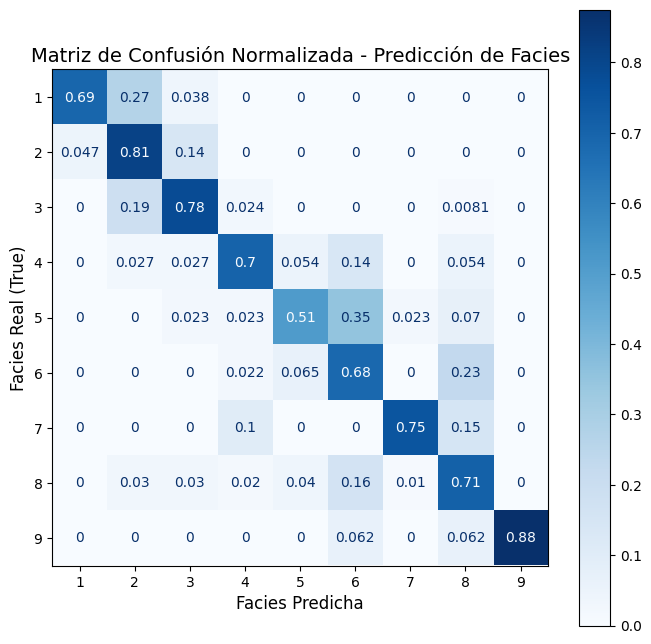

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Crear la figura y graficar la matriz de confusión del mejor modelo
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=sorted(y.unique()),
    cmap='Blues',
    normalize='true', # Muestra porcentajes por clase para ver dónde falla el recall
    ax=ax
)

plt.title('Matriz de Confusión Normalizada - Predicción de Facies', fontsize=14)
plt.xlabel('Facies Predicha', fontsize=12)
plt.ylabel('Facies Real (True)', fontsize=12)
plt.show()

En la diagonal principal (desde arriba a la izquierda hasta abajo a la derecha),los números más altos (como 0.81, 0.78, 0.88) se concentran allí, lo que indica que el modelo acierta la gran mayoría de las veces.
Las **facies 9** (0.88) y la **2** (0.81) son las que el modelo reconoce con mayor precisión.
Luego se observan confusiones geológicas comunes en **las facies 5 y la 6** (un 0.35 de las veces el modelo predice un 6 cuando en realidad era 5). Esto tiene todo el sentido en petrofísica, ya que litofacies con propiedades poroso-permeables similares generan respuestas de rayos gamma y densidad muy parecidas, lo que dificulta su separación automática.